# Task 6 –  Data Science Business Insights Dashboard

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = r"D:\Desktop\Ausify Technologies Internship\Task 1 Data Cleaning\Output\netflix_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (8790, 12)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   show_id         8790 non-null   object
 1   type            8790 non-null   object
 2   title           8790 non-null   object
 3   director        8790 non-null   object
 4   country         8790 non-null   object
 5   date_added      8790 non-null   object
 6   release_year    8790 non-null   int64 
 7   rating          8790 non-null   object
 8   duration        8790 non-null   object
 9   listed_in       8790 non-null   object
 10  duration_value  8790 non-null   int64 
 11  duration_unit   8790 non-null   object
dtypes: int64(2), object(10)
memory usage: 824.2+ KB

Missing Values:
show_id           0
type              0
title             0
director          0
country           0
date_added        0
release_year      0
rating            0
duration          0
listed

In [4]:
# Create a working copy
business_df = df.copy()

# Convert date_added into datetime
business_df['date_added'] = pd.to_datetime(
    business_df['date_added'].str.strip(),
    errors='coerce'
)

# Extract year and month of addition
business_df['added_year'] = business_df['date_added'].dt.year
business_df['added_month'] = business_df['date_added'].dt.month
business_df['added_month_name'] = business_df['date_added'].dt.month_name()

print("Date conversion completed!")
print("\nDate range:")
print(business_df['date_added'].min(), "to", business_df['date_added'].max())

print("\nNew columns:")
print(business_df[['date_added', 'added_year', 'added_month',
                   'added_month_name']].head())

Date conversion completed!

Date range:
2008-01-01 00:00:00 to 2021-09-25 00:00:00

New columns:
  date_added  added_year  added_month added_month_name
0 2021-09-25        2021            9        September
1 2021-09-24        2021            9        September
2 2021-09-24        2021            9        September
3 2021-09-22        2021            9        September
4 2021-09-24        2021            9        September


In [5]:
print("Records with invalid or missing addition dates:",
      business_df['date_added'].isna().sum())

print("\nContent types:")
print(business_df['type'].value_counts())

print("\nContent addition years:")
print(business_df['added_year'].value_counts().sort_index())

Records with invalid or missing addition dates: 0

Content types:
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64

Content addition years:
added_year
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1648
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64


In [6]:
# Business KPIs

total_titles = len(business_df)

total_movies = (business_df['type'] == 'Movie').sum()
total_tv_shows = (business_df['type'] == 'Tv Show').sum()

movie_percentage = (total_movies / total_titles) * 100
tv_percentage = (total_tv_shows / total_titles) * 100

unique_countries = business_df['country'].nunique()
unique_genres = business_df['listed_in'].nunique()

average_release_year = business_df['release_year'].mean()

print("NETFLIX BUSINESS INSIGHTS")
print("-------------------------")
print("Total Titles:", total_titles)
print("Total Movies:", total_movies)
print("Total TV Shows:", total_tv_shows)
print("Movie Percentage:", round(movie_percentage, 2), "%")
print("TV Show Percentage:", round(tv_percentage, 2), "%")
print("Unique Country Entries:", unique_countries)
print("Unique Genre Combinations:", unique_genres)
print("Average Release Year:", round(average_release_year, 2))

NETFLIX BUSINESS INSIGHTS
-------------------------
Total Titles: 8790
Total Movies: 6126
Total TV Shows: 2664
Movie Percentage: 69.69 %
TV Show Percentage: 30.31 %
Unique Country Entries: 86
Unique Genre Combinations: 513
Average Release Year: 2014.18


In [7]:
yearly_additions = (
    business_df.groupby('added_year')
    .size()
    .reset_index(name='total_titles')
)

print(yearly_additions)

    added_year  total_titles
0         2008             2
1         2009             2
2         2010             1
3         2011            13
4         2012             3
5         2013            11
6         2014            24
7         2015            82
8         2016           426
9         2017          1185
10        2018          1648
11        2019          2016
12        2020          1879
13        2021          1498


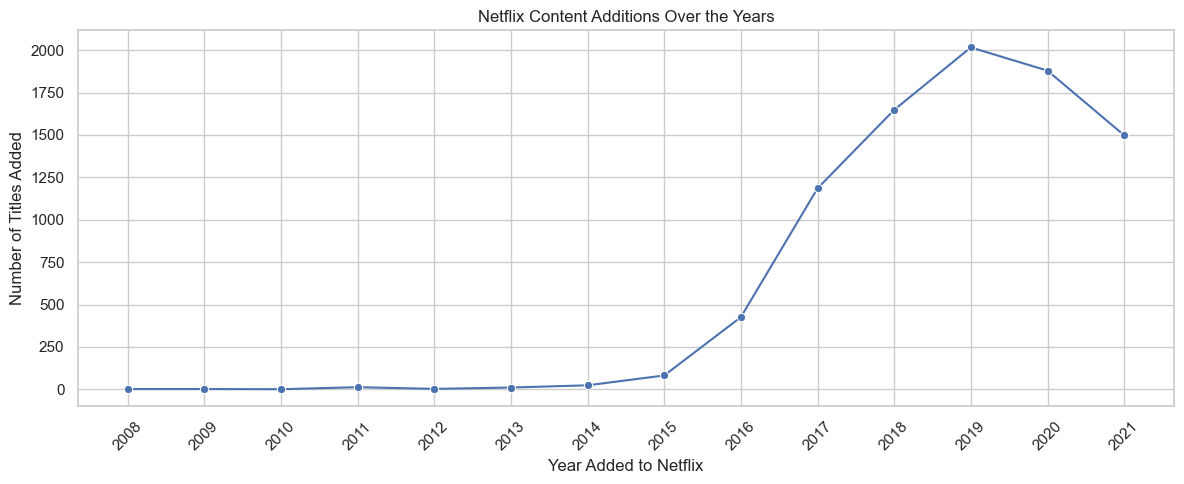

In [8]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=yearly_additions,
    x='added_year',
    y='total_titles',
    marker='o'
)

plt.title('Netflix Content Additions Over the Years')
plt.xlabel('Year Added to Netflix')
plt.ylabel('Number of Titles Added')
plt.xticks(yearly_additions['added_year'], rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Country-wise content analysis

country_df = business_df[
    business_df['country'] != 'Unknown'
].copy()

# Split multiple countries into individual entries
country_df['country'] = country_df['country'].str.split(',')

country_df = country_df.explode('country')

country_df['country'] = country_df['country'].str.strip()

top_countries = (
    country_df.groupby('country')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("TOP 10 COUNTRIES BY TITLE COUNT")
print(top_countries)

TOP 10 COUNTRIES BY TITLE COUNT
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
dtype: int64


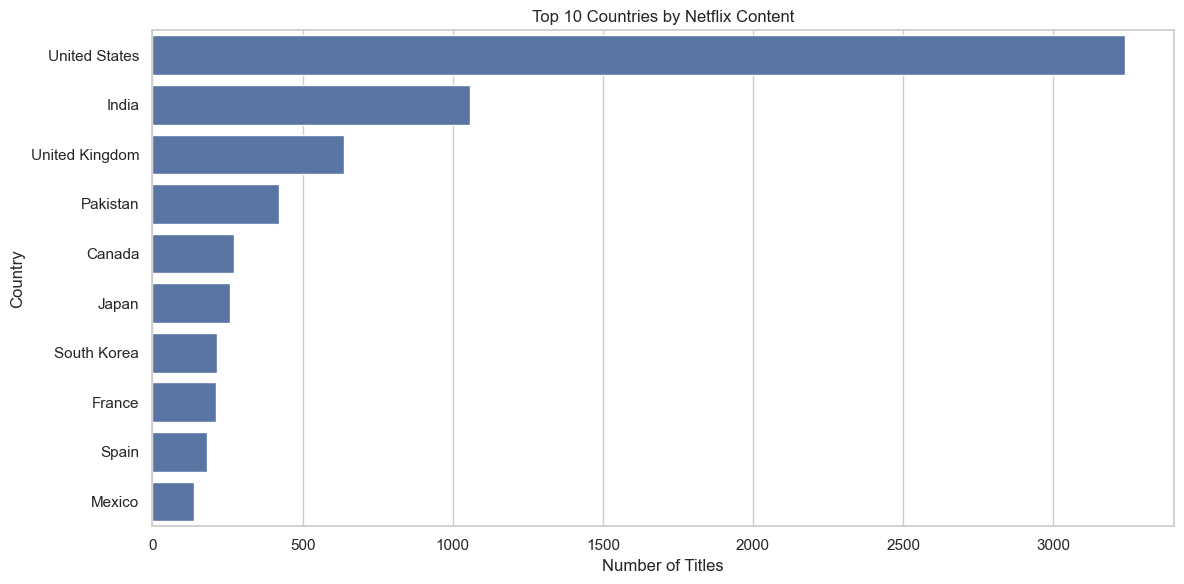

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [11]:
genre_df = business_df[['listed_in']].copy()

genre_df['listed_in'] = genre_df['listed_in'].str.split(',')

genre_df = genre_df.explode('listed_in')

genre_df['listed_in'] = genre_df['listed_in'].str.strip()

top_genres = (
    genre_df['listed_in']
    .value_counts()
    .head(10)
)

print("TOP 10 GENRES")
print(top_genres)

TOP 10 GENRES
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


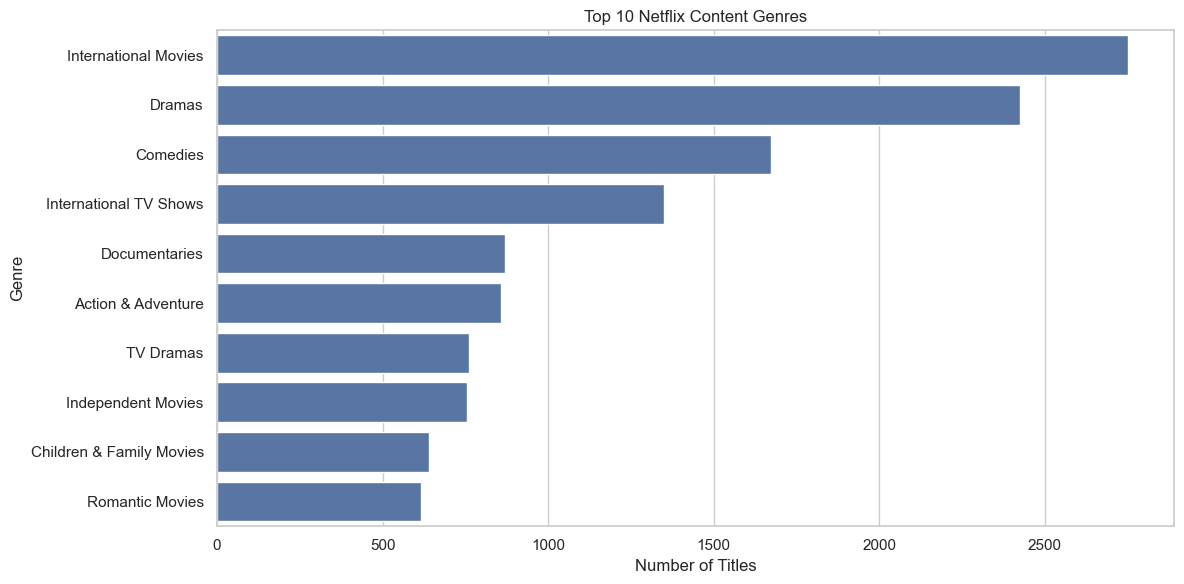

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Netflix Content Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [13]:
country_df = business_df[
    business_df['country'] != 'Unknown'
].copy()

country_df['country'] = country_df['country'].str.split(',')
country_df = country_df.explode('country')
country_df['country'] = country_df['country'].str.strip()

top_countries = (
    country_df.groupby('country')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print(top_countries)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
dtype: int64


In [14]:
genre_df = business_df[['listed_in']].copy()

genre_df['listed_in'] = genre_df['listed_in'].str.split(',')
genre_df = genre_df.explode('listed_in')
genre_df['listed_in'] = genre_df['listed_in'].str.strip()

top_genres = genre_df['listed_in'].value_counts().head(10)

print(top_genres)

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


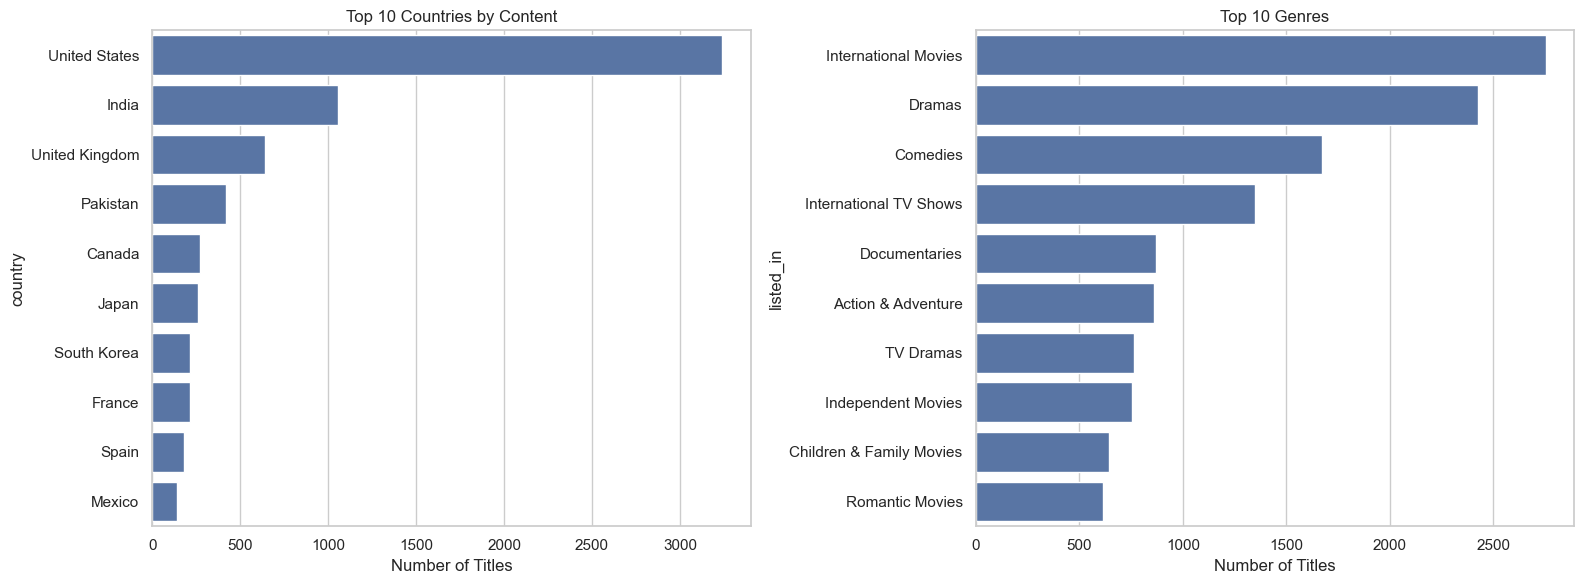

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    ax=axes[0]
)
axes[0].set_title('Top 10 Countries by Content')
axes[0].set_xlabel('Number of Titles')

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    ax=axes[1]
)
axes[1].set_title('Top 10 Genres')
axes[1].set_xlabel('Number of Titles')

plt.tight_layout()
plt.show()

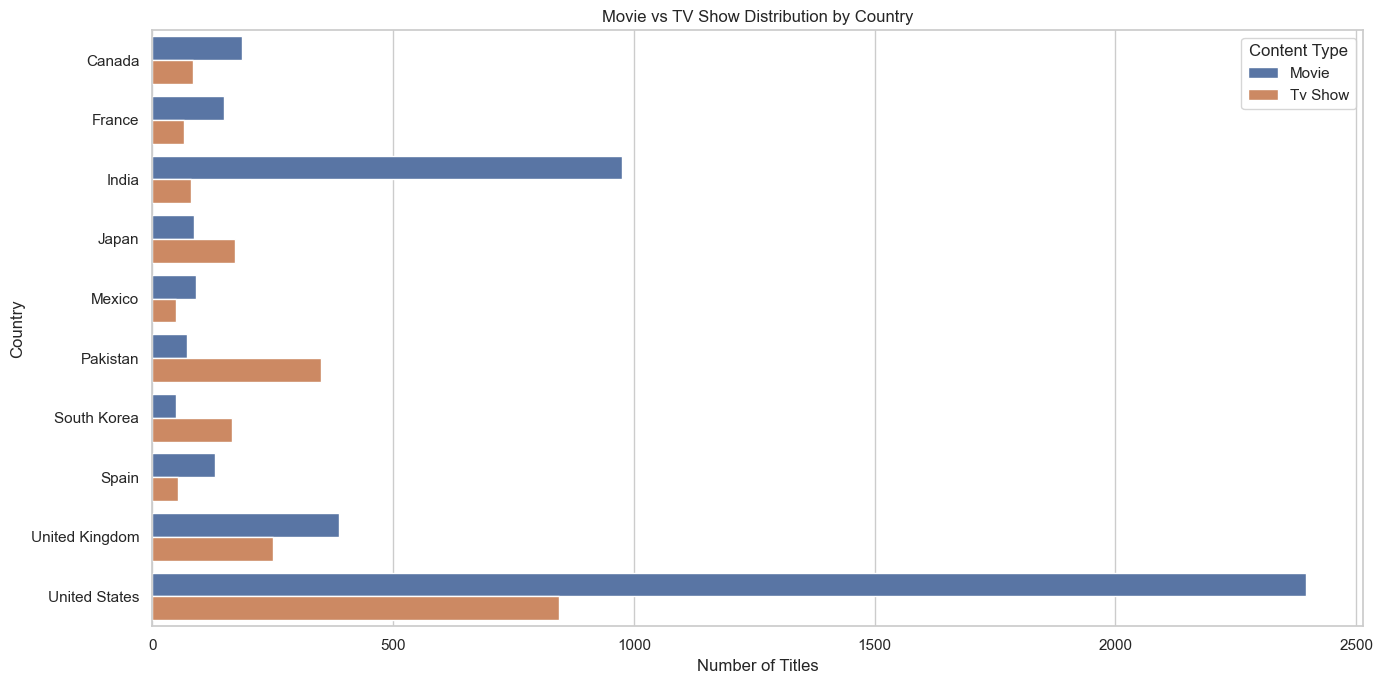

In [16]:
# Content type distribution by country

country_type = (
    country_df.groupby(['country', 'type'])
    .size()
    .reset_index(name='total_titles')
)

top_10_country_names = top_countries.index.tolist()

country_type_top10 = country_type[
    country_type['country'].isin(top_10_country_names)
]

plt.figure(figsize=(14, 7))

sns.barplot(
    data=country_type_top10,
    x='total_titles',
    y='country',
    hue='type'
)

plt.title('Movie vs TV Show Distribution by Country')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.legend(title='Content Type')
plt.tight_layout()
plt.show()

In [17]:
rating_counts = business_df['rating'].value_counts().head(10)

print("TOP 10 CONTENT RATINGS")
print(rating_counts)

TOP 10 CONTENT RATINGS
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64


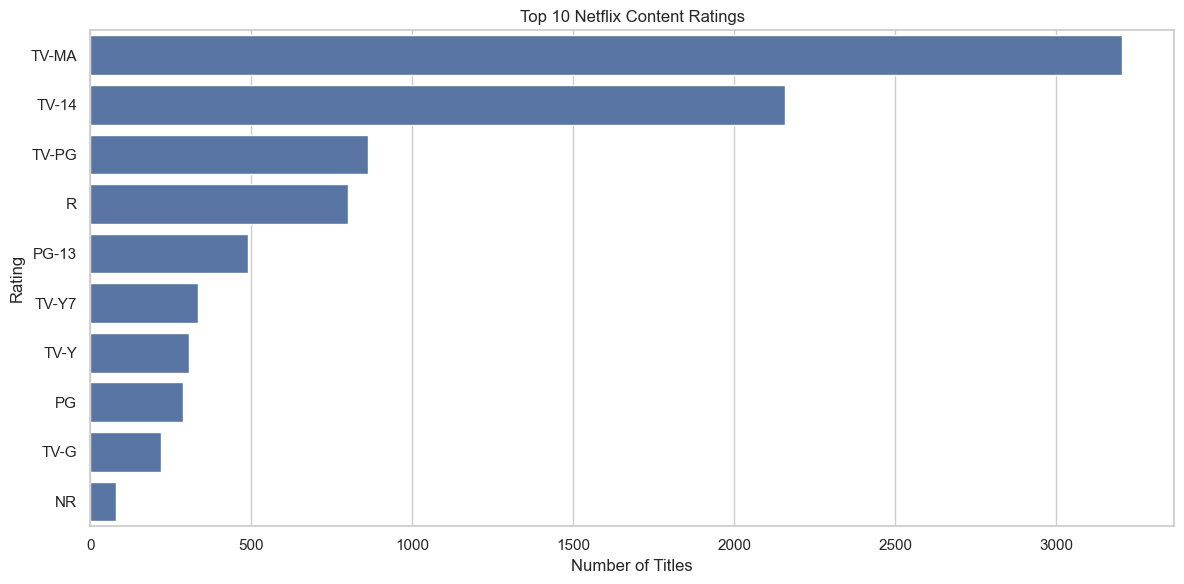

In [18]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)

plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Number of Titles')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()

In [19]:
# Count titles added each year

yearly_data = (
    business_df.groupby('added_year')
    .size()
    .reset_index(name='total_titles')
)

print(yearly_data)

    added_year  total_titles
0         2008             2
1         2009             2
2         2010             1
3         2011            13
4         2012             3
5         2013            11
6         2014            24
7         2015            82
8         2016           426
9         2017          1185
10        2018          1648
11        2019          2016
12        2020          1879
13        2021          1498


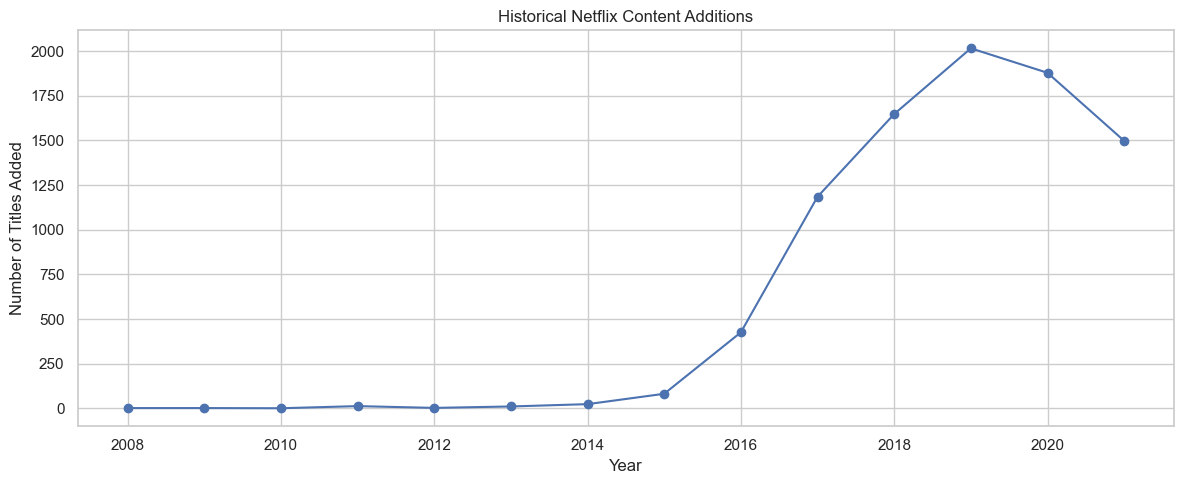

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_data['added_year'],
    yearly_data['total_titles'],
    marker='o'
)

plt.title('Historical Netflix Content Additions')
plt.xlabel('Year')
plt.ylabel('Number of Titles Added')
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Training data: 2008–2018
train_data = yearly_data[yearly_data['added_year'] <= 2018]

# Testing data: 2019–2021
test_data = yearly_data[yearly_data['added_year'] >= 2019]

X_train = train_data[['added_year']]
y_train = train_data['total_titles']

X_test = test_data[['added_year']]
y_test = test_data['total_titles']

# Train model
trend_model = LinearRegression()
trend_model.fit(X_train, y_train)

# Predict test values
y_pred = trend_model.predict(X_test)

print("Model trained successfully!")

Model trained successfully!


In [22]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

MODEL EVALUATION
----------------
MAE: 572.74
RMSE: 657.78
R2 Score: -8.009


In [23]:
# Compare actual and predicted values

prediction_comparison = pd.DataFrame({
    'Year': X_test['added_year'].values,
    'Actual Titles': y_test.values,
    'Predicted Titles': np.round(y_pred).astype(int)
})

print(prediction_comparison)

   Year  Actual Titles  Predicted Titles
0  2019           2016              1094
1  2020           1879              1225
2  2021           1498              1356


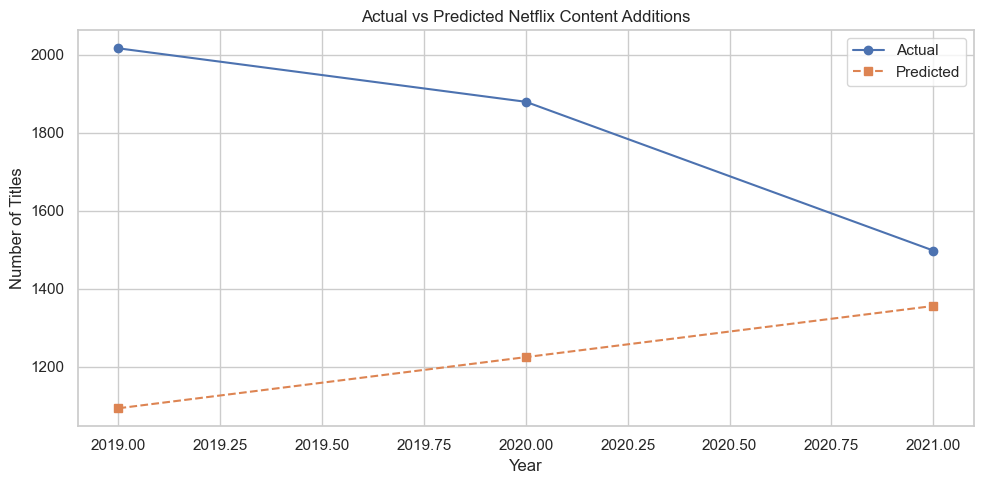

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    prediction_comparison['Year'],
    prediction_comparison['Actual Titles'],
    marker='o',
    label='Actual'
)

plt.plot(
    prediction_comparison['Year'],
    prediction_comparison['Predicted Titles'],
    marker='s',
    linestyle='--',
    label='Predicted'
)

plt.title('Actual vs Predicted Netflix Content Additions')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
baseline_predictions = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Linear Regression MAE:", round(mae, 2))

print("\nBaseline RMSE:", round(baseline_rmse, 2))
print("Linear Regression RMSE:", round(rmse, 2))

Baseline MAE: 1488.85
Linear Regression MAE: 572.74

Baseline RMSE: 1504.89
Linear Regression RMSE: 657.78


In [26]:
prediction_comparison = pd.DataFrame({
    'Year': X_test['added_year'].values,
    'Actual Titles': y_test.values,
    'Predicted Titles': np.round(y_pred).astype(int)
})

prediction_comparison['Error'] = (
    prediction_comparison['Actual Titles'] -
    prediction_comparison['Predicted Titles']
)

print(prediction_comparison)

   Year  Actual Titles  Predicted Titles  Error
0  2019           2016              1094    922
1  2020           1879              1225    654
2  2021           1498              1356    142


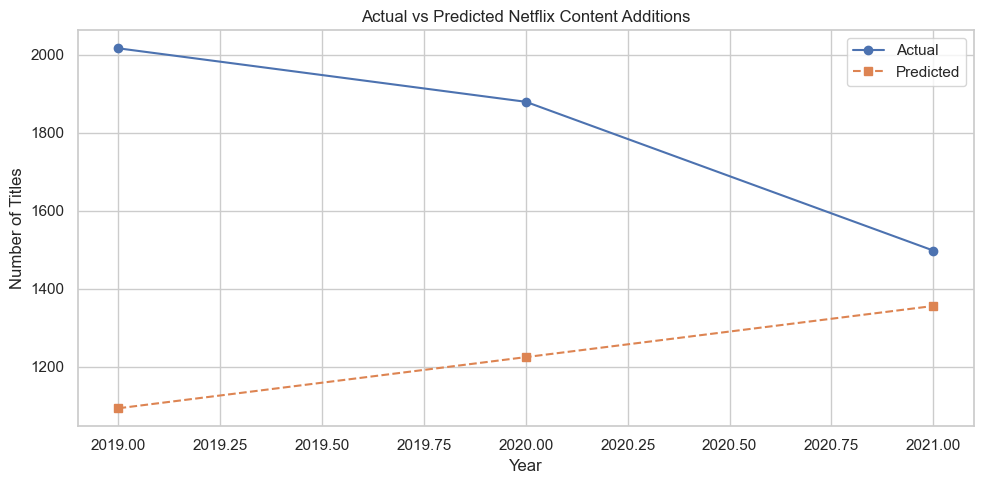

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(
    prediction_comparison['Year'],
    prediction_comparison['Actual Titles'],
    marker='o',
    label='Actual'
)

plt.plot(
    prediction_comparison['Year'],
    prediction_comparison['Predicted Titles'],
    marker='s',
    linestyle='--',
    label='Predicted'
)

plt.title('Actual vs Predicted Netflix Content Additions')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

print("Plotly imported successfully!")

Plotly imported successfully!


In [29]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


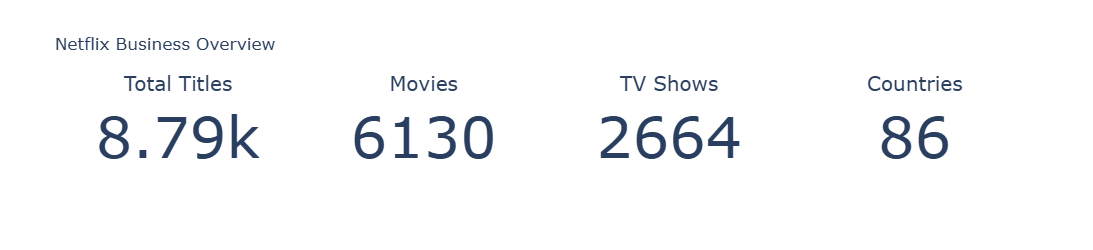

In [30]:
kpi_values = {
    'Total Titles': len(business_df),
    'Movies': (business_df['type'] == 'Movie').sum(),
    'TV Shows': (business_df['type'] == 'Tv Show').sum(),
    'Countries': business_df['country'].nunique()
}

fig = go.Figure()

colors = ['#E50914', '#2563EB', '#16A34A', '#9333EA']

for i, (label, value) in enumerate(kpi_values.items()):
    fig.add_trace(go.Indicator(
        mode="number",
        value=value,
        title={"text": label},
        domain={
            "row": 0,
            "column": i
        }
    ))

fig.update_layout(
    grid={'rows': 1, 'columns': 4, 'pattern': 'independent'},
    title="Netflix Business Overview",
    height=250
)

fig.show()

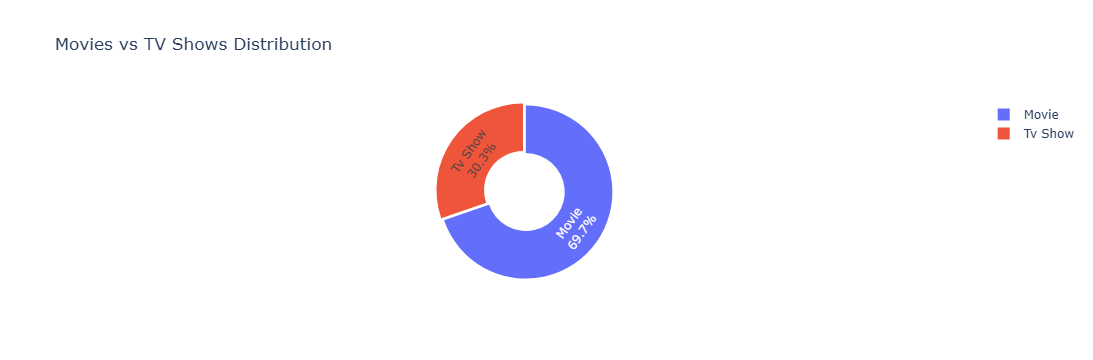

In [31]:
type_counts = business_df['type'].value_counts().reset_index()
type_counts.columns = ['Content Type', 'Count']

fig = px.pie(
    type_counts,
    names='Content Type',
    values='Count',
    title='Movies vs TV Shows Distribution',
    hole=0.45
)

fig.update_traces(
    textinfo='label+percent',
    pull=[0.04, 0]
)

fig.show()

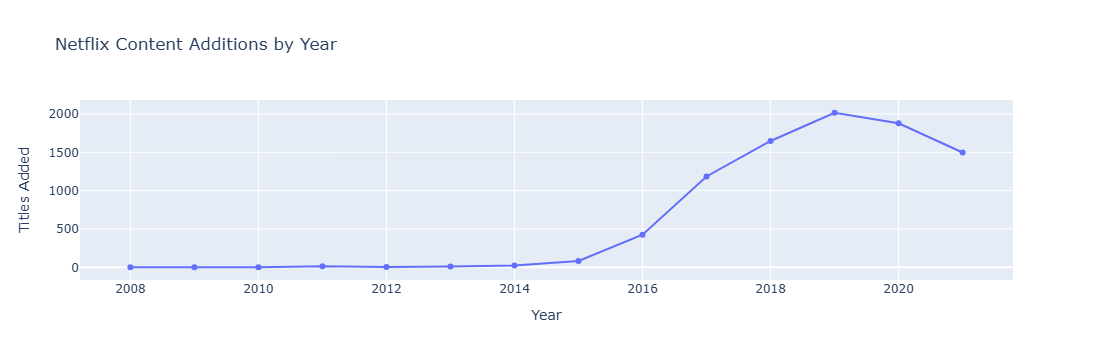

In [32]:
fig = px.line(
    yearly_data,
    x='added_year',
    y='total_titles',
    markers=True,
    title='Netflix Content Additions by Year',
    labels={
        'added_year': 'Year',
        'total_titles': 'Titles Added'
    }
)

fig.update_layout(
    hovermode='x unified'
)

fig.show()

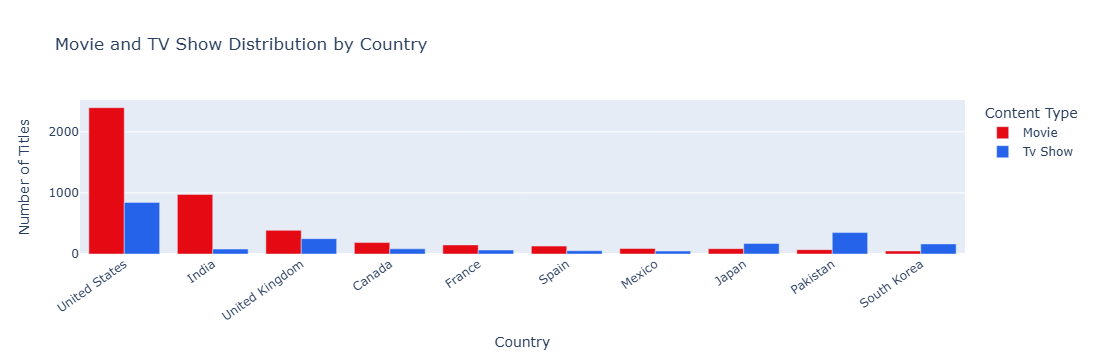

In [33]:
country_chart_data = (
    country_type_top10
    .sort_values('total_titles', ascending=False)
)

fig = px.bar(
    country_chart_data,
    x='country',
    y='total_titles',
    color='type',
    barmode='group',
    title='Movie and TV Show Distribution by Country',
    labels={
        'country': 'Country',
        'total_titles': 'Number of Titles',
        'type': 'Content Type'
    },
    color_discrete_map={
        'Movie': '#E50914',
        'Tv Show': '#2563EB'
    }
)

fig.update_layout(
    xaxis_tickangle=-35,
    hovermode='x unified'
)

fig.show()

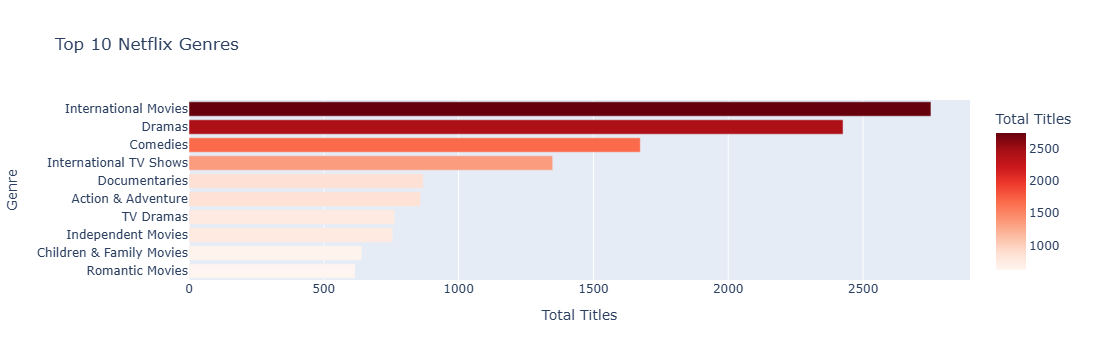

In [34]:
genre_chart_data = (
    top_genres
    .reset_index()
)

genre_chart_data.columns = ['Genre', 'Total Titles']

fig = px.bar(
    genre_chart_data.sort_values('Total Titles'),
    x='Total Titles',
    y='Genre',
    orientation='h',
    title='Top 10 Netflix Genres',
    color='Total Titles',
    color_continuous_scale='Reds'
)

fig.show()

rating_chart_data = (
    business_df['rating']
    .value_counts()
    .reset_index()
)

rating_chart_data.columns = ['Rating', 'Count']

fig = px.bar(
    rating_chart_data.head(10),
    x='Rating',
    y='Count',
    color='Count',
    title='Top 10 Netflix Content Ratings',
    color_continuous_scale='Blues'
)

fig.show()

## Business Recommendations – Netflix Content Analysis

Based on the analysis of 8,790 Netflix titles, the following recommendations can be considered:

1. **Balance content formats:** Movies represent approximately 69.69% of the catalogue, while TV Shows account for 30.31%. Netflix could evaluate opportunities to diversify its content formats based on audience demand.

2. **Strengthen regional content analysis:** The United States and India are among the largest country contributors in the dataset. Regional content strategies could be explored using additional audience and engagement data.

3. **Evaluate genre representation:** International Movies, Dramas and Comedies have strong catalogue representation. Content investment decisions should consider viewer engagement and performance rather than catalogue counts alone.

4. **Review content addition trends:** Recorded additions peaked in 2019 and declined through 2021. Netflix could investigate the factors behind these changes before making future content acquisition decisions.

5. **Use predictive models cautiously:** Linear Regression provided lower MAE and RMSE than the training-average baseline, but its negative R² indicates weak predictive performance under the standard test-set benchmark. More historical observations and advanced forecasting methods would be needed.

### Business Limitation

This analysis uses Netflix catalogue metadata. It does not include subscriber numbers, viewing hours, revenue, customer preferences or content engagement. Therefore, the recommendations are exploratory and should not be treated as confirmed business decisions.

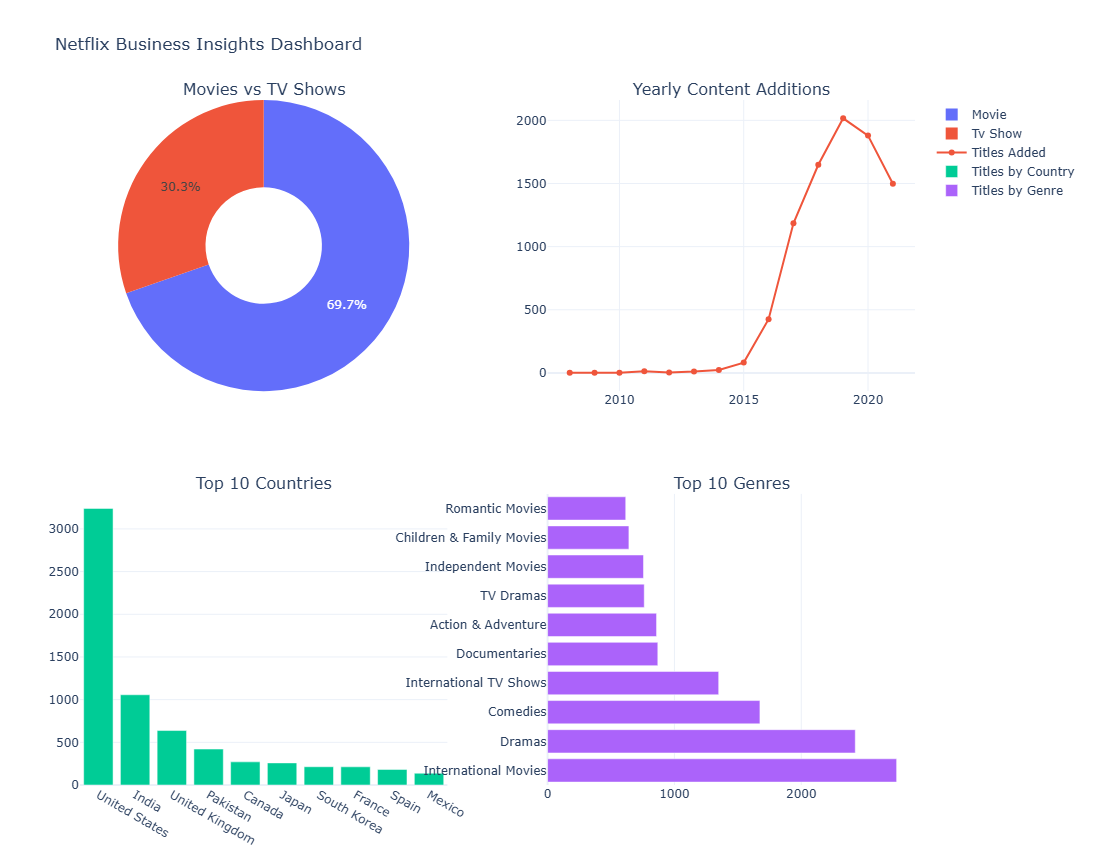

In [36]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Create a 2 x 2 dashboard
dashboard = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "domain"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "Movies vs TV Shows",
        "Yearly Content Additions",
        "Top 10 Countries",
        "Top 10 Genres"
    ),
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

# 1. Content type pie chart
type_counts = business_df['type'].value_counts()

dashboard.add_trace(
    go.Pie(
        labels=type_counts.index,
        values=type_counts.values,
        hole=0.4,
        name="Content Type"
    ),
    row=1, col=1
)

# 2. Yearly additions
dashboard.add_trace(
    go.Scatter(
        x=yearly_data['added_year'],
        y=yearly_data['total_titles'],
        mode='lines+markers',
        name='Titles Added'
    ),
    row=1, col=2
)

# 3. Top 10 countries
dashboard.add_trace(
    go.Bar(
        x=top_countries.index,
        y=top_countries.values,
        name='Titles by Country'
    ),
    row=2, col=1
)

# 4. Top 10 genres
dashboard.add_trace(
    go.Bar(
        x=top_genres.values,
        y=top_genres.index,
        orientation='h',
        name='Titles by Genre'
    ),
    row=2, col=2
)

dashboard.update_layout(
    title_text="Netflix Business Insights Dashboard",
    height=850,
    width=1200,
    showlegend=True,
    template="plotly_white"
)

dashboard.show()

In [37]:
import os

output_folder = r"D:\Desktop\Ausify Technologies Internship\Task 6 Business Insights Dashboard"

os.makedirs(output_folder, exist_ok=True)

dashboard_path = os.path.join(
    output_folder,
    "Netflix_Business_Insights_Dashboard.html"
)

dashboard.write_html(
    dashboard_path,
    include_plotlyjs=True
)

print("Dashboard saved successfully!")
print(dashboard_path)

Dashboard saved successfully!
D:\Desktop\Ausify Technologies Internship\Task 6 Business Insights Dashboard\Netflix_Business_Insights_Dashboard.html


# Netflix Business Insights Dashboard

## 1. Project Overview

This project analyzes Netflix catalogue data to identify content distribution patterns, country-wise contributions, genre trends, and yearly content additions. An interactive dashboard was developed using Python and Plotly to present the findings in a clear and accessible format.

## 2. Project Objectives

- Analyze the distribution of Movies and TV Shows.
- Identify countries contributing the most titles.
- Explore the most common Netflix genres and content ratings.
- Examine yearly trends in content additions.
- Build and evaluate a basic model to predict yearly content additions.
- Present findings through an interactive business insights dashboard.

## 3. Dataset Description

The project uses a cleaned Netflix dataset containing **8,790 records and 12 columns**.

Important columns include:
- `show_id`
- `type`
- `title`
- `director`
- `country`
- `date_added`
- `release_year`
- `rating`
- `duration`
- `listed_in`

The dataset contains Movies and TV Shows, along with information about their release years, countries, genres, ratings, and catalogue addition dates.

## 4. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Plotly
- Scikit-learn

## 5. Data Preparation

The cleaned dataset was loaded into Pandas. The `date_added` column was converted into datetime format, and additional time-based columns were created:

- `added_year`
- `added_month`
- `added_month_name`

Country and genre entries were separated into individual values for country-wise and genre-wise analysis.

## 6. Key Business Insights

### Content Type Distribution

- Total titles: 8,790
- Movies: 6,126 (69.69%)
- TV Shows: 2,664 (30.31%)

Movies represent the larger share of the Netflix catalogue in this dataset.

### Yearly Content Additions

The number of titles added increased substantially from 2016 and reached its highest level in 2019, with 2,016 titles. Additions then declined to 1,879 in 2020 and 1,498 in 2021.

### Country Analysis

The United States and India are among the leading countries by catalogue representation. Country-wise analysis helps identify markets with substantial content contributions.

### Genre Analysis

International Movies, Dramas, and Comedies are among the most represented genre categories in the dataset.

### Content Ratings

Content ratings were analyzed to understand the distribution of audience classifications across the catalogue.

## 7. Predictive Trend Analysis

A Linear Regression model was developed to estimate yearly content additions using `added_year` as the input feature and `total_titles` as the target.

The model was trained using data through 2018 and evaluated on data from 2019 onward.

### Model Evaluation

| Metric | Result |
|---|---:|
| Mean Absolute Error (MAE) | 572.74 |
| Root Mean Squared Error (RMSE) | 657.78 |
| R-squared (R²) | -8.009 |

A training-mean baseline was also evaluated:

| Metric | Baseline Result |
|---|---:|
| MAE | 1,488.85 |
| RMSE | 1,504.89 |

The Linear Regression model produced lower MAE and RMSE than this training-mean baseline. However, its negative R² indicates weak predictive performance on the test period. The model does not adequately capture changes in the yearly addition trend.

More historical observations and alternative forecasting approaches would be needed to improve the predictions.

## 8. Interactive Dashboard

An interactive dashboard was created using Plotly. It includes:

- Movies vs TV Shows distribution
- Yearly content additions
- Top 10 countries
- Top 10 genres

Additional interactive charts were also developed for country-wise content type distribution and content ratings.

The consolidated dashboard was exported as a standalone HTML file:

`Netflix_Business_Insights_Dashboard.html`

## 9. Business Recommendations

1. **Content format strategy:** Evaluate opportunities to diversify Movies and TV Shows based on audience demand and engagement data.
2. **Regional content strategy:** Investigate audience preferences in countries with substantial catalogue representation, particularly the United States and India.
3. **Genre strategy:** Use viewing and engagement data to assess investment opportunities in well-represented genres such as International Movies, Dramas, and Comedies.
4. **Trend monitoring:** Investigate the decline in yearly additions after 2019 before making catalogue expansion decisions.
5. **Predictive improvement:** Explore additional features and forecasting methods to improve yearly content addition predictions.

## 10. Limitations

This dataset contains catalogue metadata rather than detailed business performance information. It does not include subscriber numbers,